In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, log_loss
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling1D, Flatten
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input, Dropout, Flatten
from tensorflow.keras.layers import Attention, Concatenate, Multiply
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE

# data shtuff

In [2]:
#from google.colab import drive
#drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
video = pd.read_csv(r"complete_video_clean_matchingrows.csv")
audio = pd.read_csv(r"complete_audio_clean_matchingrows.csv")

In [120]:
# copy of video and audio
video_df = video.copy()
audio_df = audio.copy()

In [121]:
video_features = video_df.drop(columns=["Target"])
video_target = video_df["Target"]

audio_features = audio_df.drop(columns=["Target"])
audio_target = audio_df["Target"]

In [122]:
# Initialize MinMaxScaler
scaler_video = MinMaxScaler()
scaler_audio = MinMaxScaler()

# Apply MinMaxScaler to the features
video_features_scaled = scaler_video.fit_transform(video_features)
audio_features_scaled = scaler_audio.fit_transform(audio_features)

In [123]:
print(len(video_target))
print(len(audio_target))

568345
568345


In [124]:
# Verify that targets match after truncation
assert np.array_equal(video_target, audio_target), "Targets for video and audio do not match after truncation!"

In [125]:
# Recombine the scaled features with the target
video_df_scaled = np.hstack((video_features_scaled, video_target.values.reshape(-1, 1)))
audio_df_scaled = np.hstack((audio_features_scaled, audio_target.values.reshape(-1, 1)))

In [126]:
# Reshape video and audio data for LSTM (assuming a sequence length of 30 for both)
sequence_length_video = 30
sequence_length_audio = 30

num_features_video = video_features_scaled.shape[1]
num_features_audio = audio_features_scaled.shape[1]

In [127]:
# Reshaping the video data
X_video = video_features_scaled[:(len(video_features_scaled)//sequence_length_video)*sequence_length_video]
X_video = X_video.reshape(-1, sequence_length_video, num_features_video)
y_video = video_target.values[:(len(video_target)//sequence_length_video)*sequence_length_video]
y_video = y_video.reshape(-1, sequence_length_video)[:, 0]

# Reshaping the audio data
X_audio = audio_features_scaled[:(len(audio_features_scaled)//sequence_length_audio)*sequence_length_audio]
X_audio = X_audio.reshape(-1, sequence_length_audio, num_features_audio)
y_audio = audio_target.values[:(len(audio_target)//sequence_length_audio)*sequence_length_audio]
y_audio = y_audio.reshape(-1, sequence_length_audio)[:, 0]

In [128]:
# Ensure the target shape matches
assert np.array_equal(y_video, y_audio), "Targets for video and audio do not match!"

# Evaluation

In [129]:
# Evaluate Model
def evaluate_model(y_true, y_pred, model_name):
    print(f"Evaluation for {model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    print("Specificity:", specificity)
    print("ROC-AUC:", roc_auc_score(y_true, y_pred))

In [131]:
# Plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Confusion Matrix for {model_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [130]:
# Plotting the training and validation accuracy and loss
def plot_training_history(history, model_name):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({"font.size": 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title(f"Model Accuracy for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend(["Training", "Validation"], loc="lower right")

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title(f"Model Loss for {model_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend(["Training", "Validation"], loc="upper right")

    plt.tight_layout()
    plt.show()

In [132]:
# Plot Precision-Recall Curve
def plot_roc_recall(model, X_test, y_test, model_name):
    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
    plt.plot(fpr, tpr, color="blue", lw=2, label="ROC curve")
    plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve for {model_name}")
    plt.legend(loc="lower right")
    plt.show()

    # Plot precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_test, model.predict(X_test))
    plt.plot(recall, precision, color="blue", lw=2, label="Precision-Recall curve")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve for {model_name}")
    plt.legend(loc="lower left")
    plt.show()

# model

In [175]:
def build_bilstm_attention_branch(input_shape):
    input_layer = Input(shape=input_shape)
    bilstm = Bidirectional(LSTM(64, return_sequences=True))(input_layer)
    attention = Attention()([bilstm, bilstm])

    
    combined = Concatenate()([bilstm, attention])
    
    pooling = GlobalMaxPooling1D()(combined)

    return input_layer, pooling

In [176]:
# Define input shapes for both modalities
video_input_shape = (sequence_length_video, num_features_video)
audio_input_shape = (sequence_length_audio, num_features_audio)

In [177]:
video_input, video_branch_output = build_bilstm_attention_branch(video_input_shape)
audio_input, audio_branch_output = build_bilstm_attention_branch(audio_input_shape)

In [178]:
# Concatenate the outputs from both branches
merged = Concatenate()([video_branch_output, audio_branch_output])

In [179]:
# Dense layers after concatenation
dense = Dense(128, activation="relu")(merged)
dropout = Dropout(0.5)(dense)
output_layer = Dense(1, activation="sigmoid")(dropout)

In [180]:
# Define the multimodal model
multimodal_model = Model(inputs=[video_input, audio_input], outputs=output_layer)
multimodal_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

In [181]:
# Summary of the model
multimodal_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 30, 378)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_5       │ (None, 30, 78)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 30, 128)   │    226,816 │ input_layer_4[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_5     │ (None, 30, 128)   │     73,216 │ input_layer_5[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_4         │ (None, 30, 128)   │          0 │ bidirectional_4[… │
│ (Attention)         │                   │            │ bidirectional_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_5         │ (None, 30, 128)   │          0 │ bidirectional_5[… │
│ (Attention)         │                   │            │ bidirectional_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_23      │ (None, 30, 256)   │          0 │ bidirectional_4[… │
│ (Concatenate)       │                   │            │ attention_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_24      │ (None, 30, 256)   │          0 │ bidirectional_5[… │
│ (Concatenate)       │                   │            │ attention_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate_23[0… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate_24[0… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_25      │ (None, 512)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 128)       │     65,664 │ concatenate_25[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 128)       │          0 │ dense_22[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 1)         │        129 │ dropout_10[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 365,825 (1.40 MB)

 Trainable params: 365,825 (1.40 MB)

 Non-trainable params: 0 (0.00 B)

In [182]:
X_train_video, X_test_video, y_train, y_test = train_test_split(X_video, y_video, test_size=0.2, random_state=42)
X_train_audio, X_test_audio, _, _ = train_test_split(X_audio, y_audio, test_size=0.2, random_state=42)

In [183]:
# Train the model
history = multimodal_model.fit(
    [X_train_video, X_train_audio], y_train,
    epochs=10, batch_size=32,
    validation_data=([X_test_video, X_test_audio], y_test)
)

Epoch 1/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 66s 113ms/step - accuracy: 0.7078 - loss: 0.5874 - val_accuracy: 0.7514 - val_loss: 0.5596
Epoch 2/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 79s 106ms/step - accuracy: 0.7482 - loss: 0.5014 - val_accuracy: 0.7973 - val_loss: 0.4265
Epoch 3/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 61s 129ms/step - accuracy: 0.7881 - loss: 0.4417 - val_accuracy: 0.7474 - val_loss: 0.4749
Epoch 4/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 58s 123ms/step - accuracy: 0.8076 - loss: 0.3975 - val_accuracy: 0.8482 - val_loss: 0.3177
Epoch 5/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 84s 127ms/step - accuracy: 0.8472 - loss: 0.3388 - val_accuracy: 0.8744 - val_loss: 0.2787
Epoch 6/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 75s 111ms/step - accuracy: 0.8720 - loss: 0.2922 - val_accuracy: 0.9068 - val_loss: 0.2165
Epoch 7/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 56s 118ms/step - accuracy: 0.9040 - loss: 0.2292 - val_accuracy: 0.8897 - val_loss: 0.2665
Epoch 8/10
474/474 ━━━━━━━━━━━━━━━━━━━━ 59s 125ms/step - accuracy: 0.9053 - loss: 0

In [142]:
# Predict
y_pred_probs = multimodal_model.predict([X_test_video, X_test_audio])
y_pred = (y_pred_probs > 0.5).astype(int)

119/119 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step


In [ ]:
from tensorflow.keras.models import save_model

# Save the trained model to a file
model_path = "multimodal_bilstm_attention_model_own_split.h5"
multimodal_model.save(model_path)
print(f"Model saved to {model_path}")

In [ ]:
import pickle

history_path = "training_history_own_split.pkl"

# Save the history
with open(history_path, "wb") as file:
    pickle.dump(history.history, file)

print(f"Training history saved to {history_path}")

# results

In [184]:
# Evaluate the model
evaluate_model(y_test, y_pred, "Multimodal BiLSTM + Attention Model")

Evaluation for Multimodal BiLSTM + Attention Model
Confusion Matrix:
[[2591   21]
 [ 261  916]]
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      2612
           1       0.98      0.78      0.87      1177

    accuracy                           0.93      3789
   macro avg       0.94      0.89      0.91      3789
weighted avg       0.93      0.93      0.92      3789

Accuracy: 0.9255740300870943
Precision: 0.9775880469583778
Recall: 0.7782497875955819
F1 Score: 0.8666035950804163
Specificity: 0.9919601837672282
ROC-AUC: 0.8851049856814049


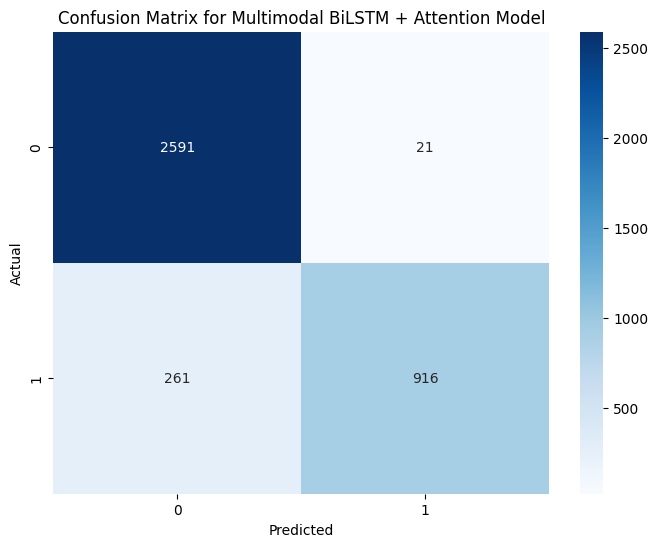

In [185]:
plot_confusion_matrix(y_test, y_pred, "Multimodal BiLSTM + Attention Model")

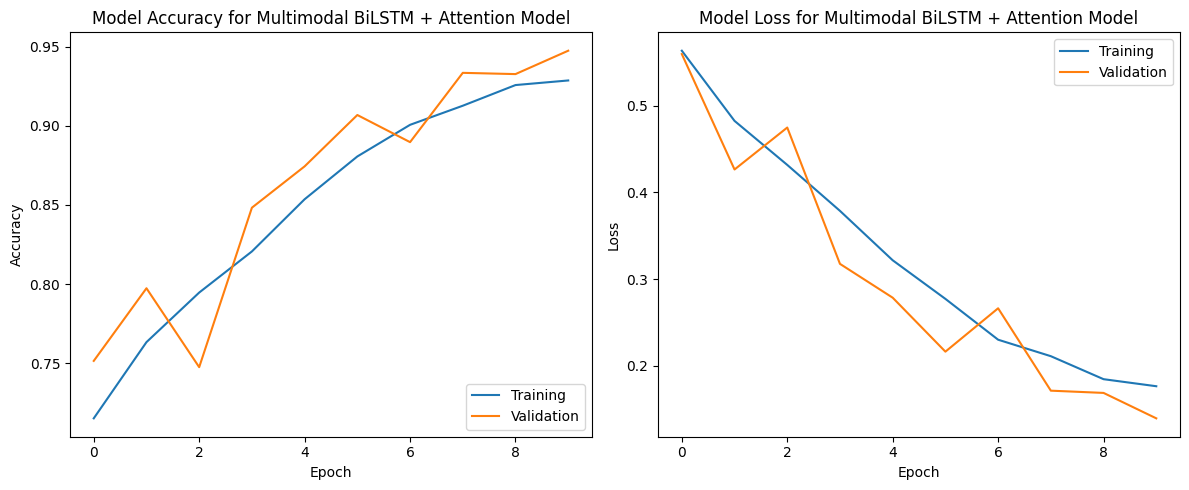

In [186]:
plot_training_history(history, "Multimodal BiLSTM + Attention Model")

119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step


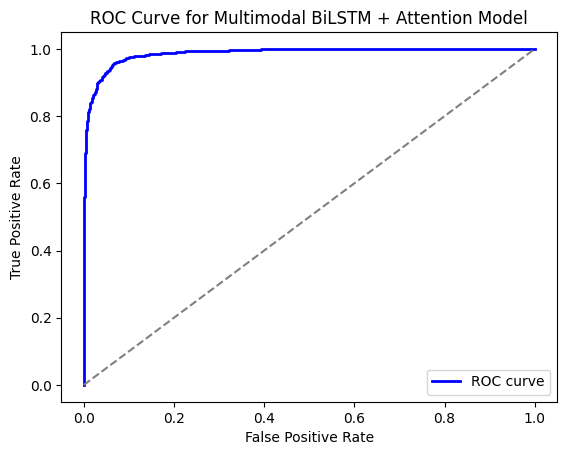

119/119 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step


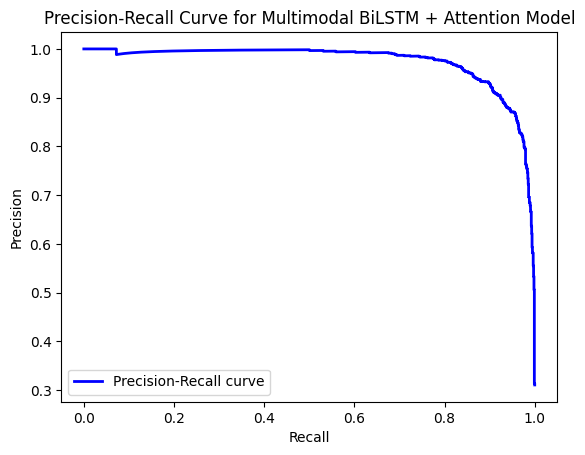

In [146]:
plot_roc_recall(multimodal_model, [X_test_video, X_test_audio], y_test, "Multimodal BiLSTM + Attention Model")